# 9. HD maps for automated driving

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/09_hdmap.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/09_hdmap.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You make the lanes of Monaco (GMNS), write them as a CommonRoad map, a Lanelet2 map and an OpenDRIVE file, and read the CommonRoad map back with commonroad-io. The module is `duckosm.hdmap`. [duckOSM for automated driving users](https://khoshkhah.github.io/duckOSM/compare/for-hdmap-users/) compares each call with the tools of the field.

| Call | Result |
|---|---|
| `net.to_gmns` | the lanes and the lane connectors (the input of the lane maps) |
| `duckosm.hdmap.to_commonroad` | a CommonRoad scenario map (`.xml`) |
| `duckosm.hdmap.to_lanelet2` | a Lanelet2 map (OSM XML) |
| `net.to_opendrive` | an ASAM OpenDRIVE file (experimental) |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook
    %pip install -q "duckosm[sim,hdmap]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
gmns = net.driving.to_gmns("out/gmns.duckdb")         # the lanes and the lane connectors (GMNS)
gmns["modes"]                                         # the rows of the GMNS tables

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

GMNS out/gmns.duckdb: done in 6.6 s

{'driving': {'node': 1772,
  'link': 2858,
  'lane': 3318,
  'movement': 3755,
  'signal_controller': 1,
  'curb_seg': 0}}

## CommonRoad

`to_commonroad` makes one lanelet for each lane (to the edge of the junction) and one for each lane connector through a junction. Each lanelet has its predecessors, its successors and the lanes on its left and right. The coordinates are metres from the center of the area.

In [3]:
cr = duckosm.hdmap.to_commonroad("out/gmns.duckdb", "out/monaco_commonroad.xml")    # the CommonRoad map
{k: v for k, v in cr.items() if k != "ids"}                                          # the numbers

{'path': PosixPath('out/monaco_commonroad.xml'),
 'lanelets': 7209,
 'lanes': 3318,
 'connectors': 4123}

In [4]:
cr["ids"].head()    # each lanelet_id, its GMNS lane or connector, and its edge_id

,lanelet_id,gmns_id,edge_id
0,1,1003228148726728921_1,1003228148726728921
1,2,1014480835261600237_1,1014480835261600237
2,3,1015158544797938083_1,1015158544797938083
3,4,1016153299111353750_1,1016153299111353750
4,5,1016294143949642362_1,1016294143949642362


In [5]:
from commonroad.common.file_reader import CommonRoadFileReader          # commonroad-io reads the file back

scenario, _ = CommonRoadFileReader("out/monaco_commonroad.xml").open()  # the scenario and its lanelets
lanelets = scenario.lanelet_network.lanelets
{"lanelets": len(lanelets), "with a successor": sum(bool(x.successor) for x in lanelets),
 "with a lane on the right": sum(x.adj_right is not None for x in lanelets)}    # the links between the lanelets

{'lanelets': 7209, 'with a successor': 6935, 'with a lane on the right': 416}

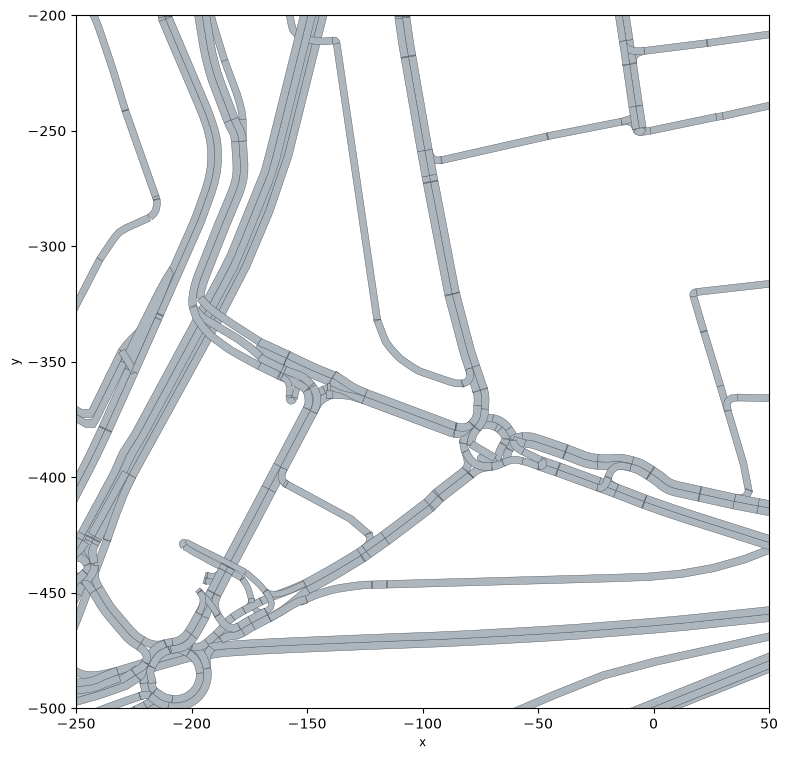

In [6]:
import geopandas as gpd
from shapely.geometry import Polygon                                     # to draw the lanelets

shapes = gpd.GeoSeries([Polygon(x.polygon.vertices) for x in lanelets])  # the outline of each lanelet, in metres
ax = shapes.plot(color="#adb5bd", edgecolor="#495057", linewidth=0.3, figsize=(9, 9))    # the lanelets
ax.set_xlim(-250, 50)                                                    # a part of the center, in metres
ax.set_ylim(-500, -200)
ax.set_aspect("equal")

## Lanelet2 and OpenDRIVE

In [7]:
import xml.etree.ElementTree as ET                                       # to read the files back

l2 = duckosm.hdmap.to_lanelet2("out/gmns.duckdb", "out/monaco_lanelet2.osm")    # the Lanelet2 map
odr = net.driving.to_opendrive("out/monaco.xodr")                                # the OpenDRIVE file
l2, len(ET.parse("out/monaco.xodr").findall("road"))                             # the numbers, and the roads in the file

OpenDRIVE out/monaco.xodr: done in 0.1 s

({'lanelets': 3318, 'ways': 6636, 'nodes': 86498}, 2840)